# 1. Patient Virtual Avatars & 6-Hour Biomarkers (Norris *et al.* Figure 3)

In Tutorial 6, we built the **193-species multiscale B-cell model** and discovered a unifying principle: whenever genetic alterations simultaneously push the **Cell Cycle** (**pro-proliferative, PP**) and block **Apoptosis** (**anti-apoptotic, AA**), they combine super-additively to drive aggressive tumour expansion.

Real patients with **Diffuse Large B-Cell Lymphoma (DLBCL)** rarely carry only one clean textbook translocation like *MYC* + *BCL2*. Instead, whole-exome sequencing (WES) typically reveals **3 to 15 co-occurring mutations and copy-number changes** scattered across NF-κB (`MYD88`, `CD79B`, `CARD11`, `TNFAIP3`, `NFKBIE`, `REL`), the cell cycle (`RB1`, `CDKN1B`, `CCNE1`, `CCNB1`), apoptosis (`BCL2`, `MCL1`, `TP53`, `BAX`, `CASP3`, `CYCS`), and differentiation (`PRDM1`/Blimp1, `BCL6`).

How can a clinician tell whether a specific patient's unique mix of mutations adds up to a dangerous **"double-hit-like" (AAPP)** signalling state?

In this tutorial, we build the **patient-specific modelling pipeline** from *Norris et al.* (**Blood Cancer Journal**, 2024, 14:105, [doi:10.1038/s41408-024-01090-y](https://www.nature.com/articles/s41408-024-01090-y)):
- **Chapter 1 (this page):** Map real DLBCL sequencing data (`patientData.csv` + `muts2ParamsNEW.csv`) into individual virtual avatars, reproduce **Figure 3**, and test personalised drug rescue predictions live.
- **Chapter 2:** Connect 6-hour simulated **AA** and **PP** biomarkers to **10-year clinical survival** across 466 real DLBCL patients (**Figures 4 & 5**).

```{figure} ../images/patient-specific-pipeline.svg
:alt: Four-stage patient-specific modelling pipeline from sequencing data to 12-hour virtual avatar simulation, 6-hour AAPP classification, and 10-year survival prediction
:width: 100%

The four stages of patient-specific lymphoma modelling in *Norris et al.* (2024). Simulating just **6 hours** of intracellular signalling (~0.6 seconds per patient) predicts **10-year clinical outcomes**.
```

:::{tip} Start your live Julia kernel
Click **Activate Live Editable Julia Cells** near the top of the page, then run each cell in order with **Shift + Enter**.
:::

---

## Why 6-Hour Single-Cell Simulations Work for Hundreds of Patients

In Tutorial 6, running a 20-cell, 120-hour multiscale population simulation took ~25–35 seconds per condition. Doing 100 cells × 120 hours for 500 patients would take hours on a compute cluster.

*Norris et al.* (2024) discovered two key simplifications that allow personalised modelling to scale effortlessly to large patient cohorts (and run in seconds right here in your browser!):

1. **Deterministic single-cell avatars:** Because genetic mutations are shared stably across a patient's tumour cells, simulating **1 deterministic founder cell** per patient (with identical baseline parameters across all patients except the mutated rates) captures the patient-specific shift in signalling.
2. **Reading out early molecular biomarkers at $t = 6\text{ hours}$:**
   - Six hours is late enough for NF-κB, MYC, BCL2, cell-cycle, and early apoptotic signalling to respond to the IKK activation pulse, yet **early enough that no cell has divided or died yet** (division begins around 21–24 h).
   - Three intracellular species at **6 hours** (`t = 361 min`) act as quantitative sensors of the two axes:
     - **Pro-Proliferative (`PP`) sensor — low `Cdh1`:** Lower `Cdh1` at 6 hours indicates faster progression through G1 toward S phase.
     - **Anti-Apoptotic (`AA`) sensors — low `cSmac` and low `cCytoC`:** Lower cytoplasmic SMAC and Cytochrome c release from mitochondria indicates stronger resistance to apoptosis.

---

## Step 1: Build the Patient-Specific 193-Species Model (With IKK/NF-κB Scaling)

In the patient pipeline, upstream NF-κB activating mutations — such as **`MYD88 L265P`**, **`CD79B`**, **`CARD11`**, **`BCL10`**, and **`TNFAIP3`** (A20) loss — map to `"k2_scalingNumber-NFkB"`, which multiplies the active **NEMO:IKK** input signal.

We include an explicit `ikk_scale_slot` at the end of our typed `Vector{Float64}` parameter vector `p` so any patient's `"k2_scalingNumber-NFkB"` multiplier scales `ikkSS(t)` and `ikkTC(t)` directly with zero runtime overhead!

In [1]:
using DifferentialEquations
using Plots
using CSV
using DataFrames
using Statistics

gr()

function build_patient_model(base_dir::AbstractString="multiscale")
    modules = ["NFkB", "cellCycle", "apoptosis", "differentiation"]
    mod_dir = joinpath(base_dir, "moduleDefinitionFiles")
    comb_dir = "combinedPatientModel"
    mkpath(comb_dir)

    link_rxn = CSV.read(joinpath(mod_dir, "linking", "reactions.csv"), DataFrame; stringtype=String, types=String)
    link_par = CSV.read(joinpath(mod_dir, "linking", "parameters.csv"), DataFrame; stringtype=String, types=String)
    link_rl  = CSV.read(joinpath(mod_dir, "linking", "rateLaws.csv"), DataFrame; stringtype=String, types=String)
    replace!(link_rxn.Substrate, missing => "")
    replace!(link_rxn.Products,  missing => "")

    link_par[:, 1] = link_par[:, 1] .* "-linking"
    link_rxn.Parameters = [ismissing(p) ? missing : join([x * "-linking" for x in split(p, " ")], " ") for p in link_rxn.Parameters]

    rxn_all, par_all, rl_all = copy(link_rxn), copy(link_par), copy(link_rl)

    for m in modules
        r_df = CSV.read(joinpath(mod_dir, m, "reactions.csv"), DataFrame; stringtype=String, types=String)
        p_df = CSV.read(joinpath(mod_dir, m, "parameters.csv"), DataFrame; stringtype=String, types=String)
        l_df = CSV.read(joinpath(mod_dir, m, "rateLaws.csv"), DataFrame; stringtype=String, types=String)
        replace!(r_df.Substrate, missing => "")
        replace!(r_df.Products,  missing => "")

        drop_r = [i for (i, row) in enumerate(eachrow(r_df))
                  if any((link_rxn.Substrate .== row.Substrate) .& (link_rxn.Products .== row.Products))]
        delete!(r_df, drop_r)
        r_df.Parameters = [ismissing(p) ? missing : join([x * "-" * m for x in split(p, " ")], " ") for p in r_df.Parameters]
        append!(rxn_all, r_df)

        drop_p = [i for (i, row) in enumerate(eachrow(p_df))
                  if any(link_par.parameter .== row.parameter) || occursin("p[", row.value)]
        delete!(p_df, drop_p)
        p_df.parameter = p_df.parameter .* ("-" * m)
        append!(par_all, p_df)
        append!(rl_all, l_df)
    end

    CSV.write(joinpath(comb_dir, "reactions.csv"),  rxn_all)
    CSV.write(joinpath(comb_dir, "parameters.csv"), par_all)
    CSV.write(joinpath(comb_dir, "rateLaws.csv"),   rl_all)

    run(`python3 $(joinpath(base_dir, "csv2model-multiscale.py")) $(joinpath(comb_dir, "reactions.csv")) $(joinpath(comb_dir, "parameters.csv")) $(joinpath(comb_dir, "rateLaws.csv")) odeMultiscaleModel.jl param`)
    return comb_dir
end

comb_dir = build_patient_model("multiscale")
include("variableNames.jl")
tdfunc = t -> 0.0
include("scanIncludes.jl")
include("multiscale/fixSpecies.jl")

idx(name) = findfirst(==(name), syms)
const idx_Rb      = idx("Rb")
const idx_E2FRb   = idx("E2F_Rb")
const idx_pE2FRb  = idx("pE2F_Rb")
const idx_HypoPRb = idx("HypoP_Rb")
const idx_r31Sw   = idx("r31switch")
const idx_Cdh1    = idx("Cdh1")
const idx_Mass    = idx("Mass")
const idx_GM      = idx("GM")
const idx_IRF4    = idx("IRF4")
const idx_AID     = idx("AID")
const idx_Blimp1  = idx("Blimp1")
const idx_Pax5    = idx("Pax5")
const idx_Bcl6    = idx("Bcl6")
const idx_Bcl2t   = idx("Bcl2t")
const idx_Ligand  = idx("L")
const idx_cMyct   = idx("cMyct")
const idx_RelAp50n = idx("RelAnp50n")
const idx_cSmac   = idx("cSmac")
const idx_cCytoC  = idx("cCytoC")

fixSpecies("odeMultiscaleModel.jl",  "odeMultiscaleTC.jl", idx_Ligand)
fixSpecies("odeMultiscaleTC.jl",     "odeMultiscaleSS.jl", idx_Bcl2t)
for s_i in (idx_IRF4, idx_AID, idx_Blimp1, idx_Bcl6, idx_Pax5)
    fixSpecies("odeMultiscaleSS.jl", "odeMultiscaleSS.jl", s_i)
end

const totalIKK = 280.0
const basalIKK = totalIKK / 100.0
const IKKParamTime = Float64[0, 15, 30, 45, 60, 90, 120, 240, 360, 600, 1440, 2880, 4320, 5760, 7200, 8640, 14400]
const IKKParamVals = Float64[1, 1, 2, 7, 13, 19, 32, 29, 27, 20, 10, 1, 0, 0, 0, 0, 0] ./ 100.0

function ikkTC(t::Float64)::Float64
    t <= IKKParamTime[1] && return IKKParamVals[1] * totalIKK
    t >= IKKParamTime[end] && return IKKParamVals[end] * totalIKK
    @inbounds for i in 1:(length(IKKParamTime) - 1)
        if t <= IKKParamTime[i + 1]
            frac = (t - IKKParamTime[i]) / (IKKParamTime[i + 1] - IKKParamTime[i])
            return max(IKKParamVals[i] + frac * (IKKParamVals[i + 1] - IKKParamVals[i]), 0.0) * totalIKK
        end
    end
    return 0.0
end
ikkSS(t::Float64)::Float64 = basalIKK

# Append an IKK scaling slot (p[end]) so MYD88 / CD79B / CARD11 / TNFAIP3 scale NEMO:IKK cleanly
const td_indices = [i for (i, v) in enumerate(paramVals) if !(v isa Real)]
const ikk_scale_slot = length(paramVals) + 1
for (src, dst, fn_name, ikk_name) in [
    ("odeMultiscaleSS.jl", "odeSS_pat.jl", "odeSS_pat!", "ikkSS"),
    ("odeMultiscaleTC.jl", "odeTC_pat.jl", "odeTC_pat!", "ikkTC"),
]
    c = read(src, String)
    c = replace(c, "function odeMultiscaleModel!" => "function $fn_name")
    for ti in td_indices
        c = replace(c, "p[$ti](t)" => "($(ikk_name)(t) * p[$ikk_scale_slot])")
    end
    c = replace(c, r"maximum\(\[([^,\]]+),0\]\)" => s"max(\1, 0.0)")
    write(dst, c)
end
include("odeSS_pat.jl")
include("odeTC_pat.jl")

const base_p = vcat(Float64[v isa Real ? Float64(v) : 0.0 for v in paramVals], [1.0])
const idx_NIKdeg = findfirst(==("k1_NIKConstDeg-NFkB"), parameterNameList)

const base_y0 = zeros(Float64, length(syms))
for row in eachrow(CSV.read("multiscale/initialConditions/fullModelInits.csv", DataFrame; header=false))
    i = idx(String(row[1]))
    !isnothing(i) && (base_y0[i] = Float64(row[2]))
end

function cond_rb(u, t, integrator)
    num = u[idx_Rb] + u[idx_E2FRb] + u[idx_pE2FRb]
    den = num + u[idx_HypoPRb]
    return (num / max(den, 1e-12)) - 0.8
end
aff_rb_pos!(integ) = (integ.u[idx_r31Sw] = 0.0)
aff_rb_neg!(integ) = (integ.u[idx_r31Sw] = 1.0)
cond_cdh(u, t, integrator) = u[idx_Cdh1] - 0.2
function aff_cdh_ss!(integ)
    integ.u[idx_Mass] *= 0.5
    integ.u[idx_GM]   *= 0.5
    integ.u[idx_r31Sw] = 1.0
    integ.u[idx_Bcl2t] = 277.0
    integ.u[idx_Cdh1]  = 1.0
end

const cb_rb  = ContinuousCallback(cond_rb, aff_rb_pos!, aff_rb_neg!)
const cbs_ss = CallbackSet(cb_rb, ContinuousCallback(cond_cdh, aff_cdh_ss!, nothing))
const f_ss   = ODEFunction(odeSS_pat!)
const f_tc   = ODEFunction(odeTC_pat!)
const pat_alg = Rodas5P(autodiff=AutoFiniteDiff())

function simulate_patient_12h(mods::Dict{String, Float64}=Dict{String, Float64}())
    p = copy(base_p)
    for (k, v) in mods
        if k == "k2_scalingNumber-NFkB"
            p[ikk_scale_slot] *= v
        else
            i = findfirst(==(k), parameterNameList)
            !isnothing(i) && (p[i] *= v)
        end
    end

    y0 = copy(base_y0)
    y0[idx_Bcl2t]  = 277.0
    y0[idx_Ligand] = 0.0
    sol_ss = solve(ODEProblem(f_ss, y0, (0.0, 1440.0), p), pat_alg;
                   callback=cbs_ss, abstol=1e-5, reltol=1e-3, save_everystep=false)

    u = copy(sol_ss.u[end])
    u[idx_Cdh1]   = 1.0; u[idx_IRF4] = 0.0; u[idx_AID] = 0.0
    u[idx_Blimp1] = 0.0; u[idx_Pax5] = 1.0; u[idx_Bcl6] = 0.0; u[idx_Ligand] = 1.0
    p[idx_NIKdeg] /= 10.0

    sol = solve(ODEProblem(f_tc, u, (1.0, 721.0), p), pat_alg;
                callback=cb_rb, abstol=1e-5, reltol=1e-3, saveat=15.0)
    i6 = argmin(abs.(sol.t .- 361.0))
    u6 = sol.u[i6]
    return (
        t_h    = sol.t ./ 60.0,
        cMyct  = [x[idx_cMyct]  for x in sol.u],
        Bcl2t  = [x[idx_Bcl2t]  for x in sol.u],
        Cdh1   = [x[idx_Cdh1]   for x in sol.u],
        cSmac  = [x[idx_cSmac]  for x in sol.u],
        cCytoC = [x[idx_cCytoC] for x in sol.u],
        Cdh1_6   = u6[idx_Cdh1],
        cSmac_6  = u6[idx_cSmac],
        cCytoC_6 = u6[idx_cCytoC],
        cMyct_6  = u6[idx_cMyct],
        Bcl2t_6  = u6[idx_Bcl2t],
    )
end

println("Patient virtual avatar simulator simulate_patient_12h(mods) ready (193 species).")

param
Running CSV2JuliaDiffEq with parameters dynamically determined by a variable, re-run with the 5th argument set to 'scan' or 'inline'
Opening combinedPatientModel/rateLaws.csv as rate law file
Opening combinedPatientModel/parameters.csv as parameters file
Opening combinedPatientModel/reactions.csv as reactions file


parameters can now be searched in parameterNameList by name.
example to modify k_binding 1.5 fold higher:
indexOfParam=findfirst(x->"k_binding"==x,parameterNameList)
paramVals[indexOfParam]=paramVals[indexOfParam]*1.5


Patient virtual avatar simulator simulate_patient_12h(mods) ready (193 species).


---

## Step 2: Recreate Figure 3A–C — Upstream NF-κB Activation Mimics *Both* MYC and BCL2

Before simulating individual patients, let's test a key mechanistic prediction from **Figure 3A–C** of *Norris et al.* (2024):
- Compare **`WT`**, **`MYC × 1.5`**, **`BCL2 × 1.5`**, and an upstream **NF-κB/IKK activating mutation** (`"k2_scalingNumber-NFkB" => 1.5`, mimicking *MYD88 L265P* or *CD79B*, and `2.25×` mimicking co-occurring *MYD88 + CD79B*).
- Watch what happens to **`cMyct`**, **`Bcl2t`**, **`cSmac`**, and **`cCytoC`** over 12 hours!

Row,Condition,cMyct_6h,Bcl2t_6h,cSmac_6h,cCytoC_6h
,String,Float64,Float64,Float64,Float64
1,WT,8.11,71.5,1.81e-7,3.71e-6
2,MYC × 1.5,12.17,71.5,1.81e-7,3.71e-6
3,BCL2 × 1.5,8.11,96.2,8.69e-8,1.86e-6
4,IKK × 1.5 (MYD88),12.86,103.6,7.15e-8,1.56e-6
5,IKK × 2.25 (MYD88+CD79B),18.97,148.2,2.37e-8,5.47e-7


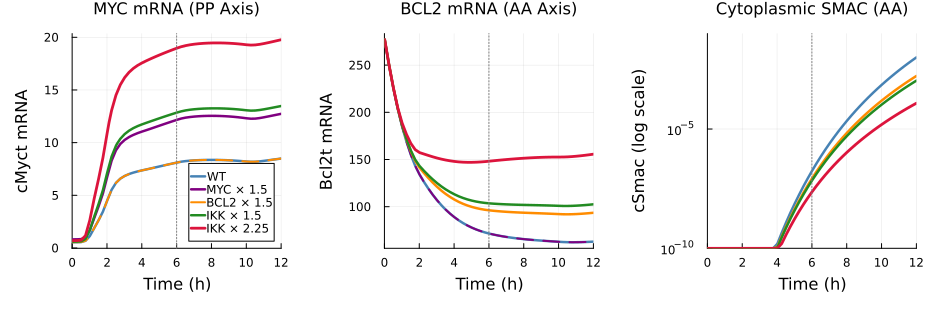

In [2]:
r_wt   = simulate_patient_12h(Dict{String, Float64}())
r_myc  = simulate_patient_12h(Dict("k1_mycExp-linking"  => 1.5))
r_bcl2 = simulate_patient_12h(Dict("k1_bcl2Exp-linking" => 1.5))
r_ikk1 = simulate_patient_12h(Dict("k2_scalingNumber-NFkB" => 1.5))
r_ikk2 = simulate_patient_12h(Dict("k2_scalingNumber-NFkB" => 2.25))

display(DataFrame(
    Condition  = ["WT", "MYC × 1.5", "BCL2 × 1.5", "IKK × 1.5 (MYD88)", "IKK × 2.25 (MYD88+CD79B)"],
    cMyct_6h   = round.([r_wt.cMyct_6, r_myc.cMyct_6, r_bcl2.cMyct_6, r_ikk1.cMyct_6, r_ikk2.cMyct_6], digits=2),
    Bcl2t_6h   = round.([r_wt.Bcl2t_6, r_myc.Bcl2t_6, r_bcl2.Bcl2t_6, r_ikk1.Bcl2t_6, r_ikk2.Bcl2t_6], digits=1),
    cSmac_6h   = [round(r.cSmac_6, sigdigits=3)  for r in (r_wt, r_myc, r_bcl2, r_ikk1, r_ikk2)],
    cCytoC_6h  = [round(r.cCytoC_6, sigdigits=3) for r in (r_wt, r_myc, r_bcl2, r_ikk1, r_ikk2)],
))

p_m = plot(r_wt.t_h, r_wt.cMyct, lw=2.5, color=:steelblue, label="WT")
plot!(p_m, r_myc.t_h,  r_myc.cMyct,  lw=2.5, color=:purple, label="MYC × 1.5")
plot!(p_m, r_bcl2.t_h, r_bcl2.cMyct, lw=2.0, color=:darkorange, linestyle=:dash, label="BCL2 × 1.5")
plot!(p_m, r_ikk1.t_h, r_ikk1.cMyct, lw=2.5, color=:forestgreen, label="IKK × 1.5")
plot!(p_m, r_ikk2.t_h, r_ikk2.cMyct, lw=2.8, color=:crimson, label="IKK × 2.25")
vline!(p_m, [6.0], color=:gray, linestyle=:dot, label=false)
plot!(p_m, xlabel="Time (h)", ylabel="cMyct mRNA", title="MYC mRNA (PP Axis)", titlefontsize=11, xlims=(0, 12))

p_b = plot(r_wt.t_h, r_wt.Bcl2t, lw=2.5, color=:steelblue, label=false)
plot!(p_b, r_myc.t_h,  r_myc.Bcl2t,  lw=2.0, color=:purple, linestyle=:dash, label=false)
plot!(p_b, r_bcl2.t_h, r_bcl2.Bcl2t, lw=2.5, color=:darkorange, label=false)
plot!(p_b, r_ikk1.t_h, r_ikk1.Bcl2t, lw=2.5, color=:forestgreen, label=false)
plot!(p_b, r_ikk2.t_h, r_ikk2.Bcl2t, lw=2.8, color=:crimson, label=false)
vline!(p_b, [6.0], color=:gray, linestyle=:dot, label=false)
plot!(p_b, xlabel="Time (h)", ylabel="Bcl2t mRNA", title="BCL2 mRNA (AA Axis)", titlefontsize=11, xlims=(0, 12))

p_s = plot(r_wt.t_h, max.(r_wt.cSmac, 1e-10), lw=2.5, color=:steelblue, label=false)
plot!(p_s, r_bcl2.t_h, max.(r_bcl2.cSmac, 1e-10), lw=2.5, color=:darkorange, label=false)
plot!(p_s, r_ikk1.t_h, max.(r_ikk1.cSmac, 1e-10), lw=2.5, color=:forestgreen, label=false)
plot!(p_s, r_ikk2.t_h, max.(r_ikk2.cSmac, 1e-10), lw=2.8, color=:crimson, label=false)
vline!(p_s, [6.0], color=:gray, linestyle=:dot, label=false)
plot!(p_s, xlabel="Time (h)", ylabel="cSmac (log scale)", yscale=:log10,
      title="Cytoplasmic SMAC (AA)", titlefontsize=11, xlims=(0, 12), ylims=(1e-10, 1e-1))

plot(p_m, p_b, p_s, layout=(1, 3), size=(940, 320),
     left_margin=4Plots.mm, right_margin=4Plots.mm, bottom_margin=4Plots.mm)

Look at what Figure 3A–C reveals:
- **`MYC × 1.5`** boosts only `cMyct` (`8.11 → 12.17`), leaving `Bcl2t` and `cSmac` unchanged.
- **`BCL2 × 1.5`** boosts only `Bcl2t` (`71.5 → 96.2`) and cuts cytoplasmic SMAC in half (`1.81e-7 → 8.69e-8`), leaving `cMyct` unchanged.
- **Upstream NF-κB activation (`IKK × 1.5`, e.g. *MYD88* or *CD79B*)** raises **both** `cMyct` (`12.86`) **and** `Bcl2t` (`103.6`) simultaneously — and co-occurring *MYD88 + CD79B* (`2.25×`, characteristic of aggressive **MCD / Cluster 5** DLBCL) pushes `cMyct` to `18.97` and drops `cSmac` nearly 8-fold!

---

## Step 3: Map Real DLBCL Patient Sequencing Data to Virtual Avatars (Figure 3D–F)

Now let's load the real patient genetic alteration tables from *Norris et al.* (2024):
- `multiscale/patientData.csv`: Patient IDs paired with their somatic copy-number alterations (`CNA`: `AMP` / `HETLOSS`), point mutations (`MISSENSE`, `TRUNC`), and fusions (`FUSION`).
- `multiscale/muts2ParamsNEW.csv`: The mechanistic mapping from each `(GENE, ALTERATION)` pair to its model parameter and fold-change (`1.5×` for gain-of-function / amplification; `0.5×` for loss-of-function / deletion).

Let's inspect the mapping table, build `map_patient_mutations(pid)`, and run **12 real DLBCL patients** live (takes ~8 seconds total!) to classify them into **`other`**, **`AA`**, **`PP`**, and **`AAPP`**!

Loaded 1240 patient alteration rows and 122 mechanistic mutation->parameter rules.


Row,Patient,N_Muts,Class,Muts
,String,Int64,String,String
1,DLBCL-LS3809,3,other,"CYCS:AMP, BAD:AMP, BCL2:AMP"
2,DLBCL-LS1098,7,other,"PARP1:AMP, MCL1:AMP, NFKBIE:AMP…"
3,DLBCL-LS1899,2,PP,"CCNB1:AMP, CYCS:AMP"
4,DLBCL-LS3085,2,PP,"CCNB1:AMP, REL:AMP"
5,DLBCL-DFCI_DLBCL_Goe16,1,AA,BCL2:N172S
6,DLBCL-LS1065,6,AA,"NFKBIE:AMP, NFKBIB:AMP, CCNE1:AMP…"
7,DLBCL-LS1304,2,AA,"MYD88:AMP, CD79B:Y197N"
8,DLBCL-LS146,14,AA,"MYD88:AMP, NFKBIE:AMP, CYCS:AMP…"
9,DLBCL-LS378,5,AAPP,"CCNB1:AMP, CYCS:AMP, RB1:HETLOSS…"


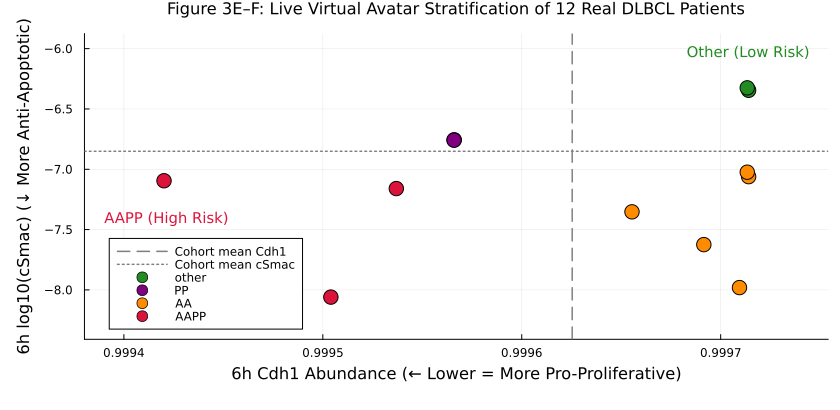

In [3]:
pat_df = CSV.read("multiscale/patientData.csv", DataFrame)
dropmissing!(pat_df)

m2p_df = CSV.read("multiscale/muts2ParamsNEW.csv", DataFrame)
filter!(r -> String(r.PARAMETER) != "0", m2p_df)
const mut_lookup = Dict(
    (String(r.GENE), String(r.ALTERATION)) => (String(r.PARAMETER), Float64(r.AMOUNT))
    for r in eachrow(m2p_df)
)

println("Loaded ", nrow(pat_df), " patient alteration rows and ", length(mut_lookup), " mechanistic mutation->parameter rules.")

function map_patient_mutations(pid::AbstractString)
    sub = unique(filter(r -> String(r.PATIENT) == pid, pat_df), [:GENE, :ALTERATION])
    mods = Dict{String, Float64}()
    matched = String[]
    for r in eachrow(sub)
        key = (String(r.GENE), String(r.ALTERATION))
        if haskey(mut_lookup, key)
            param, amt = mut_lookup[key]
            # Multiple mutations hitting the same parameter combine multiplicatively
            mods[param] = get(mods, param, 1.0) * amt
            push!(matched, "$(key[1]):$(key[2])")
        end
    end
    return (mods=mods, matched=matched)
end

# Simulate 12 real DLBCL patients spanning diverse mutation profiles (~8 seconds total!)
sample_patients = [
    "DLBCL-LS3809",           # BAD/BCL2/CYCS amp
    "DLBCL-LS1098",           # BAX/CCNE1/CYCS/MCL1/NFKBIB amp
    "DLBCL-LS1899",           # CCNB1/CYCS amp
    "DLBCL-LS3085",           # CCNB1/REL amp
    "DLBCL-DFCI_DLBCL_Goe16", # BCL2 N172S
    "DLBCL-LS1065",           # CASP3 loss, NFKBIB/E amp, etc.
    "DLBCL-LS1304",           # CD79B Y197N + MYD88 amp (2.25x IKK)
    "DLBCL-LS146",            # MYD88 + BCL2 + MCL1 + TP53 + CCNE1
    "DLBCL-LS378",            # BCL6 fusion + MYD88 S243N + RB1 loss + CCNB1
    "DLBCL-LS2089",           # MYD88 L265P + BCL2 + RB1 loss + CCNE1 + TP53
    "DLBCL-LS2305",           # CDKN1B(p27) loss + MCL1 + CCNB1 + CYCS
    "DLBCL-RICOVER_401",      # TNFAIP3 trunc + TP53 + MCL1 + CDKN1B(p27) loss + CCNB1
]

pat_results = NamedTuple[]
for pid in sample_patients
    info = map_patient_mutations(pid)
    sim  = simulate_patient_12h(info.mods)
    push!(pat_results, (
        Patient   = pid,
        N_Muts    = length(info.matched),
        Cdh1_6h   = sim.Cdh1_6,
        cSmac_6h  = sim.cSmac_6,
        cCytoC_6h = sim.cCytoC_6,
        Muts      = join(info.matched[1:min(3, end)], ", ") * (length(info.matched) > 3 ? "…" : ""),
    ))
end

res_df = DataFrame(pat_results)
# Classify against this 12-patient cohort's mean thresholds (exact Norris et al. rule!)
const th_cdh1  = mean(res_df.Cdh1_6h)
const th_smac  = mean(res_df.cSmac_6h)
const th_cyto  = mean(res_df.cCytoC_6h)

res_df.PP = res_df.Cdh1_6h .< th_cdh1
res_df.AA = (res_df.cSmac_6h .< th_smac) .& (res_df.cCytoC_6h .< th_cyto)
res_df.Class = [r.AA && r.PP ? "AAPP" : (r.AA ? "AA" : (r.PP ? "PP" : "other")) for r in eachrow(res_df)]

display(res_df[:, [:Patient, :N_Muts, :Class, :Muts]])

# Figure 3E-F style 2D biomarker map: AA (log10 cSmac) vs PP (Cdh1) with explicit tight axes
cls_colors = Dict("AAPP" => :crimson, "AA" => :darkorange, "PP" => :purple, "other" => :forestgreen)
x_lo, x_hi = minimum(res_df.Cdh1_6h) - 0.00004, maximum(res_df.Cdh1_6h) + 0.00004
y_lo, y_hi = log10(minimum(res_df.cSmac_6h)) - 0.35, log10(maximum(res_df.cSmac_6h)) + 0.45

p_map = plot(
    xlabel="6h Cdh1 Abundance (← Lower = More Pro-Proliferative)",
    ylabel="6h log10(cSmac) (↓ More Anti-Apoptotic)",
    title="Figure 3E–F: Live Virtual Avatar Stratification of 12 Real DLBCL Patients",
    titlefontsize=11, xlims=(x_lo, x_hi), ylims=(y_lo, y_hi),
    size=(840, 410), left_margin=4Plots.mm, bottom_margin=4Plots.mm, legend=:bottomleft,
)
vline!(p_map, [th_cdh1], color=:gray, linestyle=:dash, lw=1.5, label="Cohort mean Cdh1")
hline!(p_map, [log10(th_smac)], color=:gray, linestyle=:dot, lw=1.5, label="Cohort mean cSmac")

for cls in ("other", "PP", "AA", "AAPP")
    sub = filter(r -> r.Class == cls, res_df)
    isempty(sub) && continue
    scatter!(p_map, sub.Cdh1_6h, log10.(sub.cSmac_6h), ms=8, color=cls_colors[cls],
             markerstrokewidth=1.2, label=cls)
end
annotate!(p_map, x_lo + 0.00001, log10(th_smac) - 0.55, text("AAPP (High Risk)", 10, :crimson, :left))
annotate!(p_map, x_hi - 0.00001, y_hi - 0.15,          text("Other (Low Risk)", 10, :forestgreen, :right))
p_map

Look at that 2D molecular map — **all four patient phenotypes** emerge automatically from real patient mutations in ~8 seconds:
- **`AAPP` (bottom-left quadrant, red):** Patients such as `DLBCL-RICOVER_401` (`TNFAIP3` + `TP53` + `MCL1` + `CDKN1B` p27 loss + `CCNB1`), `DLBCL-LS2305` (`CDKN1B` loss + `MCL1` + `CCNB1`), and `DLBCL-LS378` (`BCL6` fusion + `MYD88` + `RB1` loss) drive **both** low `Cdh1` (faster G1) and low `cSmac`/`cCytoC` (blocked apoptosis) — **even without a classic *MYC* + *BCL2* translocation!**
- **`AA` only (bottom-right, orange):** Patients such as `DLBCL-DFCI_DLBCL_Goe16` (`BCL2 N172S`) and `DLBCL-LS146` suppress `cSmac`/`cCytoC` strongly without lowering `Cdh1` below the cohort mean.
- **`PP` only (top-left, purple):** Patients such as `DLBCL-LS1899` and `DLBCL-LS3085` lower `Cdh1` without suppressing mitochondrial SMAC/CytoC release.
- **`other` (top-right, green):** Patients such as `DLBCL-LS3809` and `DLBCL-LS1098` sit above the mean on both axes (including pro-apoptotic `BAX`/`BAD`/`CYCS` amplifications that counter `BCL2`/`MCL1`).

---

## Interactive Exercise: Personalised Virtual Drug Testing on an `AAPP` Patient!

Because mechanistic ODE models are interpretable **"glass-box" avatars**, we can test **personalised targeted therapies** directly on an individual patient's simulated tumour!

Take high-risk `AAPP` patient **`DLBCL-RICOVER_401`** (`TNFAIP3` loss-of-function boosting NF-κB, `MCL1` + `TP53` blocking apoptosis, and `CDKN1B`/p27 loss + `CCNB1` accelerating the cell cycle).

**Your task:** Edit `drug_mods` below to test whether adding:
- a **BTK / IKK inhibitor** (`"k2_scalingNumber-NFkB" => 0.5`),
- **venetoclax / BH3 mimetic** (`"k1_88-apoptosis" => 0.4`), or
- a **CDK4/6 inhibitor** (`"k1_20-cellCycle" => 0.5`)

moves `DLBCL-RICOVER_401` **out of the high-risk `AAPP` quadrant**!

In [4]:
# Exercise: Test a targeted drug on high-risk AAPP patient DLBCL-RICOVER_401!
target_pid = "DLBCL-RICOVER_401"
drug_name  = "Untreated"
drug_mods  = Dict{String, Float64}()   # <-- Try Dict("k1_88-apoptosis" => 0.4) or Dict("k1_20-cellCycle" => 0.5) or Dict("k2_scalingNumber-NFkB" => 0.5)

base_info = map_patient_mutations(target_pid)
treated_mods = copy(base_info.mods)
for (k, v) in drug_mods
    treated_mods[k] = get(treated_mods, k, 1.0) * v
end

sim_unt = simulate_patient_12h(base_info.mods)
sim_trt = simulate_patient_12h(treated_mods)

classify_pt(s) = begin
    pp = s.Cdh1_6 < th_cdh1
    aa = (s.cSmac_6 < th_smac) && (s.cCytoC_6 < th_cyto)
    aa && pp ? "AAPP" : (aa ? "AA" : (pp ? "PP" : "other"))
end

display(DataFrame(
    State     = ["$(target_pid) (untreated)", "$(target_pid) + $(drug_name)"],
    Cdh1_6h   = round.([sim_unt.Cdh1_6, sim_trt.Cdh1_6], digits=6),
    cSmac_6h  = [round(sim_unt.cSmac_6, sigdigits=3), round(sim_trt.cSmac_6, sigdigits=3)],
    cCytoC_6h = [round(sim_unt.cCytoC_6, sigdigits=3), round(sim_trt.cCytoC_6, sigdigits=3)],
    Class     = [classify_pt(sim_unt), classify_pt(sim_trt)],
))

Row,State,Cdh1_6h,cSmac_6h,cCytoC_6h,Class
,String,Float64,Float64,Float64,String
1,DLBCL-RICOVER_401 (untreated),0.999504,8.72e-9,3.36e-7,AAPP
2,DLBCL-RICOVER_401 + Untreated,0.999504,8.72e-9,3.36e-7,AAPP


````{admonition} Hint
:class: dropdown tip

Try three single drugs and a combination on `DLBCL-RICOVER_401`:
- `Dict("k1_88-apoptosis" => 0.4)` (venetoclax — increases `cSmac`/`cCytoC`, lifting the AA brake)
- `Dict("k1_20-cellCycle" => 0.5)` (palbociclib / CDK4/6 inhibition — raises `Cdh1`, slowing G1)
- `Dict("k2_scalingNumber-NFkB" => 0.5)` (BTK/IKK inhibition — counters `TNFAIP3` NF-κB activation)
- Combination: `Dict("k1_88-apoptosis" => 0.4, "k1_20-cellCycle" => 0.5)`!
````

````{admonition} Reveal Solution
:class: dropdown note

```julia
drugs = [
    ("Untreated",               Dict{String, Float64}()),
    ("+ Venetoclax (BCL2 0.4×)",Dict("k1_88-apoptosis" => 0.4)),
    ("+ Palbociclib (CDK 0.5×)",Dict("k1_20-cellCycle" => 0.5)),
    ("+ IKK inhibitor (0.5×)",  Dict("k2_scalingNumber-NFkB" => 0.5)),
    ("+ Venetoclax + CDK inh",  Dict("k1_88-apoptosis" => 0.4, "k1_20-cellCycle" => 0.5)),
]

out = NamedTuple[]
for (dname, dm) in drugs
    tm = copy(base_info.mods)
    for (k, v) in dm
        tm[k] = get(tm, k, 1.0) * v
    end
    s = simulate_patient_12h(tm)
    push!(out, (Regimen=dname, Cdh1_6h=round(s.Cdh1_6, digits=6),
                cSmac_6h=round(s.cSmac_6, sigdigits=3), Class=classify_pt(s)))
end
display(DataFrame(out))
```

Notice why **personalised combination logic** matters clinically: in a patient with mutations hitting both pathways (`TNFAIP3` + `MCL1` + `CDKN1B` loss), inhibiting BCL2 raises `cSmac`/`cCytoC` (reversing `AA`), inhibiting CDK4/6 raises `Cdh1` (reversing `PP`), and combining them shifts the virtual avatar out of `AAPP` completely!
````

Now move on to **[2. From 6-Hour Simulations to 10-Year Clinical Survival (Norris *et al.* Figures 4 & 5)](./02-predicting-clinical-survival-figures4-5.ipynb)** to see how these exact 6-hour biomarkers stratify real DLBCL patient survival!